# 📊 Impacto de las redes sociales en los estudiantes

**Laboratorio de Métodos Cuantitativos Aplicados a la Gestión · Trabajo práctico grupal**

Este notebook muestra los hallazgos de nuestro grupo respecto al uso de redes sociales y cómo impactan a los estudiantes.

**Dataset utilizado:** *Students Social Media Addiction* (`data/raw/dataset_final`).

### Estructura del notebook

| Parte | Tema | Pregunta de investigación |
|---|---|---|
| 1 | Preparación y exploración general | Carga y revisión del dataset |
| 2 | Nivel de desarrollo del país | ¿El impacto de las redes sociales es igual para todos los estudiantes según el nivel de desarrollo de su país? |
| 3 | Sueño y rendimiento académico | ¿El uso de redes sociales impacta en el sueño y en el rendimiento académico? |
| 4 | Plataformas y brecha de género | ¿Hay redes sociales que impactan más que otras y existe una brecha de género en ese impacto? |
| 5 | Relaciones sentimentales | ¿El uso de redes sociales afecta las relaciones sentimentales de los estudiantes? |
| 6 | Síntesis final | Resumen de las respuestas y conclusión general |

---
**Aclaración:** en todo el trabajo un valor más alto de `Mental_Health_Score` representa un _**mejor**_ estado de salud mental.

# Parte 1 | Preparación y exploración general del dataset

En esta parte se importan las librerías, se carga el dataset y se realiza una primera inspección general: estructura, tipos de datos, valores faltantes y duplicados.

## 1.1 | Preparación del análisis

En esta primera etapa se importan las librerías necesarias y se carga el dataset utilizado en el trabajo.

El objetivo es verificar que los datos hayan sido importados correctamente y conocer su estructura antes de comenzar con el análisis.

In [1]:
# Librerías necesarias:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo común para todos los gráficos del notebook
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlepad": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Paleta apta para daltonismo: cada categoría mantiene su color en todo el trabajo
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
COLOR = AZUL                                     # gráficos de una sola serie
COLORES_DESARROLLO = {"Desarrollado": AZUL, "En desarrollo": NARANJA}
COLORES_AFECTA = {"No": AZUL, "Sí": NARANJA}
COLORES_GENERO = {"Mujeres": AZUL, "Varones": NARANJA}
COLORES_ESTADO = {"Soltero/a": AZUL, "En pareja": NARANJA, "Complicado": VERDE}

# Nombres en castellano para las categorías que aparecen en los gráficos
NOMBRES = {"Female": "Mujeres", "Male": "Varones", "Yes": "Sí", "No": "No",
           "Single": "Soltero/a", "In Relationship": "En pareja", "Complicated": "Complicado"}

# Etiquetas de ejes que se repiten en varios gráficos
ETQ_USO = "Uso diario de redes sociales (horas)"
ETQ_USO_PROM = "Uso diario promedio (horas)"
ETQ_SUENO = "Horas de sueño por noche"
ETQ_SALUD = "Puntaje de salud mental (más alto = mejor)"
ETQ_SALUD_PROM = "Puntaje promedio de salud mental (más alto = mejor)"

In [2]:
# Cargamos directamente el dataset elegido desde nuestro repositorio.

url = "https://raw.githubusercontent.com/Chaile-Mendez/tp-analisis-labo/main/data/raw/dataset_final"

df = pd.read_csv(url)

## 1.2 | Exploración inicial

Antes de analizar las preguntas de investigación, se realiza una inspección general del conjunto de datos.

Se busca identificar:

- cantidad de observaciones y variables;
- tipo de cada variable;
- presencia de valores faltantes;
- posibles duplicados;
- distribución inicial de las variables relevantes.

Esta etapa permite detectar problemas de calidad de datos y definir qué transformaciones serán necesarias para el análisis posterior.

In [3]:
# Muestro las primeras filas de nuestro dataset

df.head()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0,NaN
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2,NaN
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8,NaN
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0,NaN
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0,NaN


In [4]:
# Muestro las ultimas filas de nuestro dataset

df.tail()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
1738,701,20,Female,Undergraduate,Italy,4.7,TikTok,No,7.2,7.0,In Relationship
1739,702,23,Male,Graduate,Russia,6.8,Instagram,Yes,5.9,4.0,Single
1740,703,21,Female,Undergraduate,China,5.6,WeChat,Yes,6.7,6.0,In Relationship
1741,704,24,Male,Graduate,Japan,4.3,Twitter,No,7.5,8.0,Single
1742,705,19,Female,Undergraduate,Poland,6.2,Facebook,Yes,6.3,5.0,Single


In [5]:
# Definimos que tipo de datos tienen nuestro dataset

df.dtypes

Student_ID                        int64
Age                               int64
Gender                              str
Academic_Level                      str
Country                             str
Avg_Daily_Usage_Hours           float64
Most_Used_Platform                  str
Affects_Academic_Performance        str
Sleep_Hours_Per_Night           float64
Mental_Health_Score             float64
Relationship_Status                 str
dtype: object

In [6]:
# Valores faltantes
df.isna().sum().sort_values(ascending=False)

Relationship_Status             1038
Age                                0
Student_ID                         0
Gender                             0
Academic_Level                     0
Avg_Daily_Usage_Hours              0
Country                            0
Most_Used_Platform                 0
Affects_Academic_Performance       0
Sleep_Hours_Per_Night              0
Mental_Health_Score                0
dtype: int64

In [7]:
# Registros duplicados
print("Duplicados:", df.duplicated().sum())

Duplicados: 0


**Aclaración sobre duplicados:** `duplicated()` no encuentra filas repetidas porque `Relationship_Status` hace que parezcan distintas. Como se muestra en la Parte 4, al ignorar esa columna aparecen **705 registros** que corresponden a estudiantes cargados dos veces.

Las Partes 2 y 3 trabajan con las 1.743 filas, incluidos esos registros; la Parte 4 los elimina y la Parte 5 usa solo las filas con `Relationship_Status` completo. Al repetir los cálculos principales de las Partes 2 y 3 sin duplicados, los resultados cambian solo en los decimales y las conclusiones se mantienen.

### Tratamiento de la variable `Relationship_Status`

Durante la exploración inicial se observó que `Relationship_Status` es la única variable con valores faltantes.

Como no se utiliza en las Partes 2 a 4, se decidió excluirla del conjunto de variables, sin eliminar observaciones completas del dataset únicamente por la ausencia de este dato. La Parte 5, la única que necesita esta variable, vuelve a cargar el dataset.

In [8]:
faltantes_relationship = df["Relationship_Status"].isna().sum()
porcentaje_relationship = df["Relationship_Status"].isna().mean() * 100

print("Valores faltantes:", faltantes_relationship)
print(f"Porcentaje de faltantes: {porcentaje_relationship:.2f}%")

Valores faltantes: 1038
Porcentaje de faltantes: 59.55%


In [9]:
df = df.drop(columns=["Relationship_Status"]) # Elimina únicamente la columna Relationship_Status, pero mantiene todas las filas del dataset.

In [10]:
df.columns # Verificamos que efectivamente desapareció

Index(['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Country',
       'Avg_Daily_Usage_Hours', 'Most_Used_Platform',
       'Affects_Academic_Performance', 'Sleep_Hours_Per_Night',
       'Mental_Health_Score'],
      dtype='str')

In [11]:
# Mostramos estadisticas descriptivas de las columnas numericas del dataframe que efectivamente vamos a usar
df.describe()

,Student_ID,Age,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,1743.000000,1743.000000,1743.000000,1743.000000,1743.000000
mean,381.694205,20.725760,4.980034,6.781239,6.212909
std,228.749646,1.507523,1.395759,1.155781,1.152245
min,1.000000,18.000000,1.500000,3.800000,4.000000
25%,188.500000,19.000000,4.000000,5.900000,5.000000
50%,376.000000,21.000000,4.800000,6.800000,6.000000
75%,562.000000,22.000000,5.900000,7.600000,7.000000
max,1000.000000,24.000000,8.500000,9.600000,9.000000


---

# Parte 2 | ¿El impacto es igual para todos los estudiantes? Nivel de desarrollo del país

**¿Existen diferencias en el impacto de las redes sociales sobre los estudiantes según el nivel de desarrollo del país en el que viven?**

El uso de redes sociales forma parte de la vida cotidiana de los estudiantes, pero su impacto puede no ser igual para todos.

El contexto socioeconómico del país puede influir en el acceso a la tecnología, los hábitos digitales y las consecuencias asociadas al uso de redes sociales. Para analizarlo se clasifica cada país según su **nivel de desarrollo**, a partir de la clasificación por ingreso del Banco Mundial (`Nivel_Desarrollo`).

## 2.1 | Clasificación de países según nivel de desarrollo

Para analizar si el impacto de las redes sociales presenta diferencias entre países, se creará una nueva variable denominada `Nivel_Desarrollo`.

Esta variable permitirá agrupar los países del dataset en categorías según su nivel de desarrollo, facilitando posteriormente la comparación de indicadores relacionados con el uso de redes sociales, bienestar y desempeño académico.

In [12]:
# Mostramos todos los países del dataset sin que Pandas oculte filas
paises = df["Country"].value_counts()

print(paises.to_string())

Country
India              192
USA                155
Canada             112
UK                  88
Australia           80
Germany             60
France              54
Spain               54
Mexico              54
Denmark             54
Switzerland         54
Ireland             54
Turkey              54
Japan               42
Italy               42
Russia              42
Bangladesh          40
Pakistan            38
Nepal               38
Sri Lanka           38
Maldives            38
China               32
Poland              32
South Korea         26
Brazil              16
Netherlands         16
New Zealand         16
Singapore           16
Malaysia            16
UAE                 16
Finland             16
Sweden               2
Norway               2
Belgium              2
Austria              2
Portugal             2
Greece               2
Thailand             2
Vietnam              2
Philippines          2
Indonesia            2
Taiwan               2
Hong Kong            2
Isr

In [13]:
# Obtenemos una lista con los países únicos del dataset
paises_unicos = sorted(df["Country"].dropna().unique())

print(paises_unicos)
print("Cantidad de países:", len(paises_unicos))

['Afghanistan', 'Albania', 'Andorra', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Bangladesh', 'Belarus', 'Belgium', 'Bhutan', 'Bolivia', 'Bosnia', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Ecuador', 'Egypt', 'Estonia', 'Finland', 'France', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Hong Kong', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Jamaica', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kuwait', 'Kyrgyzstan', 'Latvia', 'Lebanon', 'Liechtenstein', 'Lithuania', 'Luxembourg', 'Malaysia', 'Maldives', 'Malta', 'Mexico', 'Moldova', 'Monaco', 'Montenegro', 'Morocco', 'Nepal', 'Netherlands', 'New Zealand', 'Nigeria', 'North Macedonia', 'Norway', 'Oman', 'Pakistan', 'Panama', 'Paraguay', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Qatar', 'Romania', 'Russia', 'San Marino', 'Serbia', 'Singapore', 'Slovakia', 'Slovenia',

### Criterio para clasificar los países

Para clasificar los países se utilizó como referencia la **clasificación por nivel de ingreso del Banco Mundial**, ya que es una fuente internacional estandarizada y actualizada periódicamente que permite comparar economías bajo un mismo criterio.

El Banco Mundial divide a las economías en cuatro grupos según su **Ingreso Nacional Bruto (GNI) per cápita**: ingreso bajo, ingreso medio-bajo, ingreso medio-alto e ingreso alto. Para simplificar el análisis de este trabajo, se agruparon las economías de **ingreso alto** bajo la categoría **“Desarrollado”**, mientras que las restantes se incluyeron en **“En desarrollo”**.

Se eligió este criterio porque permite construir una clasificación reproducible y menos subjetiva que una asignación manual país por país. De todos modos, se reconoce que el nivel de ingreso no representa por sí solo todas las dimensiones del desarrollo económico y social, por lo que esta simplificación constituye una limitación del análisis.

In [14]:
# Clasificamos los países según el nivel de ingreso del Banco Mundial.
# "Desarrollado" = economías de ingreso alto
# "En desarrollo" = economías de ingreso bajo, medio-bajo o medio-alto

clasificacion_paises = {

    # Desarrollados
    "Andorra": "Desarrollado",
    "Australia": "Desarrollado",
    "Austria": "Desarrollado",
    "Bahamas": "Desarrollado",
    "Bahrain": "Desarrollado",
    "Belgium": "Desarrollado",
    "Bulgaria": "Desarrollado",
    "Canada": "Desarrollado",
    "Chile": "Desarrollado",
    "Costa Rica": "Desarrollado",
    "Croatia": "Desarrollado",
    "Cyprus": "Desarrollado",
    "Czech Republic": "Desarrollado",
    "Denmark": "Desarrollado",
    "Estonia": "Desarrollado",
    "Finland": "Desarrollado",
    "France": "Desarrollado",
    "Germany": "Desarrollado",
    "Greece": "Desarrollado",
    "Hong Kong": "Desarrollado",
    "Hungary": "Desarrollado",
    "Iceland": "Desarrollado",
    "Ireland": "Desarrollado",
    "Israel": "Desarrollado",
    "Italy": "Desarrollado",
    "Japan": "Desarrollado",
    "Kuwait": "Desarrollado",
    "Latvia": "Desarrollado",
    "Liechtenstein": "Desarrollado",
    "Lithuania": "Desarrollado",
    "Luxembourg": "Desarrollado",
    "Malta": "Desarrollado",
    "Monaco": "Desarrollado",
    "Netherlands": "Desarrollado",
    "New Zealand": "Desarrollado",
    "Norway": "Desarrollado",
    "Oman": "Desarrollado",
    "Panama": "Desarrollado",
    "Poland": "Desarrollado",
    "Portugal": "Desarrollado",
    "Qatar": "Desarrollado",
    "Romania": "Desarrollado",
    "Russia": "Desarrollado",
    "San Marino": "Desarrollado",
    "Singapore": "Desarrollado",
    "Slovakia": "Desarrollado",
    "Slovenia": "Desarrollado",
    "South Korea": "Desarrollado",
    "Spain": "Desarrollado",
    "Sweden": "Desarrollado",
    "Switzerland": "Desarrollado",
    "Taiwan": "Desarrollado",
    "Trinidad": "Desarrollado",
    "UAE": "Desarrollado",
    "UK": "Desarrollado",
    "USA": "Desarrollado",
    "Uruguay": "Desarrollado",

    # En desarrollo
    "Afghanistan": "En desarrollo",
    "Albania": "En desarrollo",
    "Argentina": "En desarrollo",
    "Armenia": "En desarrollo",
    "Azerbaijan": "En desarrollo",
    "Bangladesh": "En desarrollo",
    "Belarus": "En desarrollo",
    "Bhutan": "En desarrollo",
    "Bolivia": "En desarrollo",
    "Bosnia": "En desarrollo",
    "Brazil": "En desarrollo",
    "China": "En desarrollo",
    "Colombia": "En desarrollo",
    "Ecuador": "En desarrollo",
    "Egypt": "En desarrollo",
    "Georgia": "En desarrollo",
    "Ghana": "En desarrollo",
    "India": "En desarrollo",
    "Indonesia": "En desarrollo",
    "Iraq": "En desarrollo",
    "Jamaica": "En desarrollo",
    "Jordan": "En desarrollo",
    "Kazakhstan": "En desarrollo",
    "Kenya": "En desarrollo",
    "Kosovo": "En desarrollo",
    "Kyrgyzstan": "En desarrollo",
    "Lebanon": "En desarrollo",
    "Malaysia": "En desarrollo",
    "Maldives": "En desarrollo",
    "Mexico": "En desarrollo",
    "Moldova": "En desarrollo",
    "Montenegro": "En desarrollo",
    "Morocco": "En desarrollo",
    "Nepal": "En desarrollo",
    "Nigeria": "En desarrollo",
    "North Macedonia": "En desarrollo",
    "Pakistan": "En desarrollo",
    "Paraguay": "En desarrollo",
    "Peru": "En desarrollo",
    "Philippines": "En desarrollo",
    "Serbia": "En desarrollo",
    "South Africa": "En desarrollo",
    "Sri Lanka": "En desarrollo",
    "Syria": "En desarrollo",
    "Tajikistan": "En desarrollo",
    "Thailand": "En desarrollo",
    "Turkey": "En desarrollo",
    "Ukraine": "En desarrollo",
    "Uzbekistan": "En desarrollo",
    "Venezuela": "En desarrollo",
    "Vietnam": "En desarrollo",
    "Yemen": "En desarrollo"
}

In [15]:
# Creamos la nueva variable Nivel_Desarrollo utilizando la clasificación definida anteriormente.

df["Nivel_Desarrollo"] = df["Country"].map(clasificacion_paises)

In [16]:
# Revisamos si algún país no pudo ser clasificado.

df[df["Nivel_Desarrollo"].isna()]["Country"].unique()

<StringArray>
['Vatican City']
Length: 1, dtype: str

Hay un caso especial: **Vatican City**. El Banco Mundial no lo incluye en esta clasificación por ingreso, por lo que no se lo asigna arbitrariamente a ninguno de los dos grupos: queda como faltante en `Nivel_Desarrollo` y se excluye de las comparaciones que utilizan esta variable.

In [17]:
# Observamos cuántos estudiantes quedaron en cada grupo.

df["Nivel_Desarrollo"].value_counts(dropna=False)

Nivel_Desarrollo
Desarrollado     1103
En desarrollo     638
NaN                 2
Name: count, dtype: int64

La clasificación por nivel de desarrollo permitió agrupar a la mayoría de los estudiantes en dos categorías: **1.103 estudiantes de países desarrollados** y **638 estudiantes de países en desarrollo**.

La distribución no es completamente equilibrada, ya que el grupo de países desarrollados tiene una mayor cantidad de observaciones. Esta diferencia deberá tenerse en cuenta al interpretar los resultados, especialmente en comparaciones gráficas o estadísticas entre ambos grupos.

Además, quedaron **2 observaciones sin clasificar**, correspondientes a Vatican City.

## 2.2 | Comparación de indicadores mediante agrupaciones

Una vez creada la variable `Nivel_Desarrollo`, se agrupan los estudiantes según esta variable y se calculan la **media** y la **mediana** de las horas de uso, las horas de sueño y el puntaje de salud mental, junto con la proporción de estudiantes que declaran que las redes afectan su rendimiento académico.

In [18]:
# Resumimos los principales indicadores según
# el nivel de desarrollo del país.

resumen_desarrollo = df.groupby("Nivel_Desarrollo")[
    ["Avg_Daily_Usage_Hours",
     "Sleep_Hours_Per_Night",
     "Mental_Health_Score"]
].agg(["mean", "median"]).round(2)

resumen_desarrollo

Avg_Daily_Usage_Hours        Sleep_Hours_Per_Night         \
                                  mean median                  mean median   
Nivel_Desarrollo                                                             
Desarrollado                      4.83    4.6                  6.97    7.1   
En desarrollo                     5.25    5.2                  6.45    6.3   

                 Mental_Health_Score         
                                mean median  
Nivel_Desarrollo                             
Desarrollado                    6.37    6.3  
En desarrollo                   5.94    6.0

In [19]:
# Comparamos el impacto académico percibido
# según el nivel de desarrollo del país.

pd.crosstab(
    df["Nivel_Desarrollo"],
    df["Affects_Academic_Performance"],
    normalize="index"
) * 100

Affects_Academic_Performance,No,Yes
Nivel_Desarrollo,,
Desarrollado,43.517679,56.482321
En desarrollo,25.548589,74.451411


### Interpretación de los resultados

Los estudiantes de **países en desarrollo** muestran resultados menos favorables en los cuatro indicadores: usan más las redes (5,25 horas diarias contra 4,83), duermen menos (6,45 horas contra 6,97), tienen un puntaje de salud mental más bajo (5,94 contra 6,37) y declaran con mayor frecuencia que las redes afectan su rendimiento académico (74 % contra 56 %).

Estos resultados describen diferencias observadas dentro de la muestra y no permiten establecer relaciones causales.

## 2.3 | Visualización de resultados

Para complementar el análisis descriptivo, se grafican los principales indicadores según el nivel de desarrollo del país.

### 2.3.1 | Uso diario de redes sociales según nivel de desarrollo

Este gráfico compara el **promedio de horas diarias de uso de redes sociales** entre estudiantes de países desarrollados y países en desarrollo.

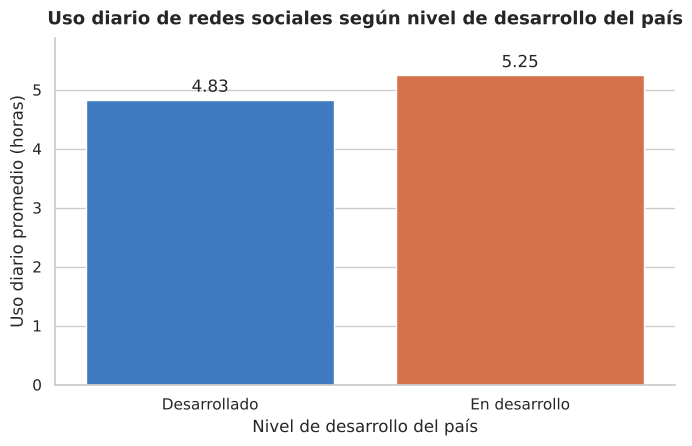

In [20]:
# Calculamos el promedio de uso diario según el nivel de desarrollo del país.
uso_desarrollo = (
    df.groupby("Nivel_Desarrollo")["Avg_Daily_Usage_Hours"]
      .mean()
      .reset_index()
)

fig, ax = plt.subplots()
sns.barplot(data=uso_desarrollo, x="Nivel_Desarrollo", y="Avg_Daily_Usage_Hours",
            hue="Nivel_Desarrollo", palette=COLORES_DESARROLLO, legend=False, ax=ax)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.2f", padding=3)   # valor sobre cada barra

ax.margins(y=0.12)                                 # espacio para los valores sobre las barras
ax.set_title("Uso diario de redes sociales según nivel de desarrollo del país")
ax.set_xlabel("Nivel de desarrollo del país")
ax.set_ylabel(ETQ_USO_PROM)
plt.show()

**Interpretación:**  
El gráfico muestra diferencias en el promedio de horas diarias de uso de redes sociales entre estudiantes de países desarrollados y en desarrollo. Los estudiantes pertenecientes a **países en desarrollo presentan un mayor promedio de uso diario**, lo que indica una mayor exposición a las redes sociales dentro de la muestra analizada.

Este resultado aporta evidencia descriptiva de una diferencia entre ambos grupos, aunque no permite afirmar que el nivel de desarrollo del país sea la causa de un mayor uso de redes sociales.

### 2.3.2 | Salud mental según nivel de desarrollo

En este gráfico se compara el **puntaje promedio de salud mental** entre estudiantes de países desarrollados y en desarrollo.

Dado que los valores más altos indican una mejor salud mental, la comparación permite observar si alguno de los grupos presenta indicadores de bienestar mental relativamente menos favorables.

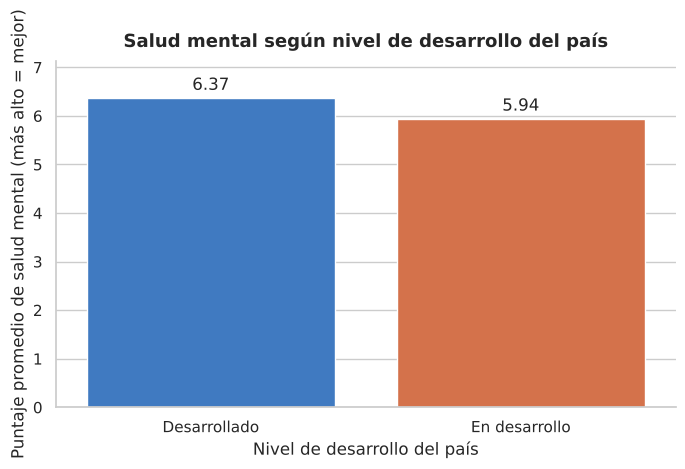

In [21]:
# Comparamos el puntaje promedio de salud mental entre países desarrollados y en desarrollo.
salud_desarrollo = (
    df.groupby("Nivel_Desarrollo")["Mental_Health_Score"]
      .mean()
      .reset_index()
)

fig, ax = plt.subplots()
sns.barplot(data=salud_desarrollo, x="Nivel_Desarrollo", y="Mental_Health_Score",
            hue="Nivel_Desarrollo", palette=COLORES_DESARROLLO, legend=False, ax=ax)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.2f", padding=3)

ax.margins(y=0.12)
ax.set_title("Salud mental según nivel de desarrollo del país")
ax.set_xlabel("Nivel de desarrollo del país")
ax.set_ylabel(ETQ_SALUD_PROM)
plt.show()

**Interpretación:**  
Al comparar el puntaje promedio de salud mental según el nivel de desarrollo del país, se observa que los estudiantes de **países en desarrollo presentan un puntaje promedio menor** que aquellos pertenecientes a países desarrollados.

Dado que en este análisis un valor más alto de `Mental_Health_Score` representa un mejor estado de salud mental, este resultado sugiere que los estudiantes de países en desarrollo presentan un indicador de bienestar mental relativamente menos favorable dentro de la muestra. Sin embargo, esta diferencia representa una asociación descriptiva y no permite establecer una relación causal.

### 2.3.3 | Distribución de las horas de sueño según nivel de desarrollo

Para ampliar la comparación, se analiza la distribución de las **horas de sueño por noche**.

Se utiliza un diagrama de caja (*boxplot*) porque permite comparar la mediana, la dispersión y la presencia de posibles valores extremos entre ambos grupos.

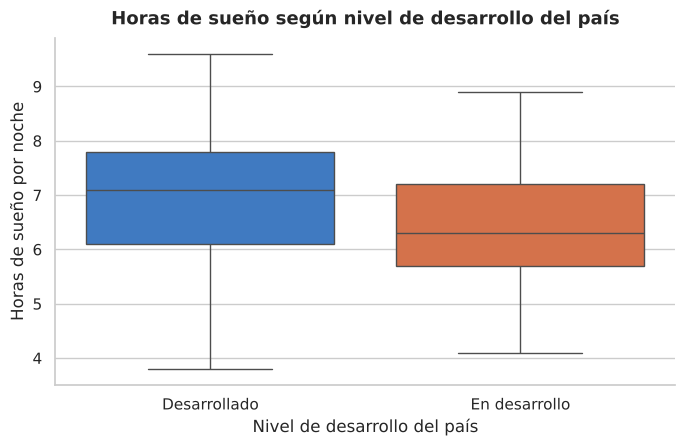

In [22]:
# Comparamos la distribución de las horas de sueño
# entre estudiantes de países desarrollados y en desarrollo.
fig, ax = plt.subplots()
sns.boxplot(data=df, x="Nivel_Desarrollo", y="Sleep_Hours_Per_Night",
            hue="Nivel_Desarrollo", palette=COLORES_DESARROLLO, legend=False, ax=ax)

ax.set_title("Horas de sueño según nivel de desarrollo del país")
ax.set_xlabel("Nivel de desarrollo del país")
ax.set_ylabel(ETQ_SUENO)
plt.show()

**Interpretación:**
Los estudiantes de **países en desarrollo duermen menos**: su mediana es de 6,3 horas por noche, contra 7,1 horas en los países desarrollados. Además, la mitad central de cada grupo (la caja) se ubica más abajo en los países en desarrollo (entre 5,7 y 7,2 horas) que en los desarrollados (entre 6,1 y 7,8 horas), mientras que la dispersión es parecida en ambos grupos.

## 2.4 | Conclusión (nivel de desarrollo del país)

El impacto de las redes sociales no es igual para todos los estudiantes. Quienes viven en **países en desarrollo** presentan, en promedio, más horas de uso, menos horas de sueño, un puntaje de salud mental más bajo y una mayor afectación académica percibida, es decir, un perfil menos favorable dentro de la muestra analizada.

Sin embargo, estos resultados deben interpretarse con cautela:

- la clasificación se construyó solo a partir del nivel de ingreso del Banco Mundial, lo que simplifica un concepto multidimensional como el desarrollo;
- los grupos están desbalanceados (1.103 estudiantes de países desarrollados contra 638 de países en desarrollo);
- el análisis es descriptivo: permite identificar asociaciones, pero no establecer que el nivel de desarrollo del país sea la causa de los resultados observados.

---

# Parte 3 | Uso de redes sociales, sueño y rendimiento académico

Esta parte analiza dos preguntas relacionadas:

- ¿El uso de redes sociales tiene un impacto en las horas de sueño?
- ¿Ese impacto se relaciona con el rendimiento académico?

Se trabaja con las mismas 1.743 filas de la Parte 2. El rendimiento académico se mide con `Affects_Academic_Performance`, que indica si el estudiante **declara** que las redes afectan su rendimiento; es una percepción y no una medición de sus notas. Por eso, en los gráficos se habla de **impacto académico percibido**.

## 3.1 | Cómo repercute el uso de redes sociales en el sueño

Se cree comúnmente que el uso de pantallas durante períodos prolongados repercute negativamente en el sueño. Para comprobarlo, se ubica a cada estudiante según sus horas de uso y de sueño, y se agrega una recta de tendencia.

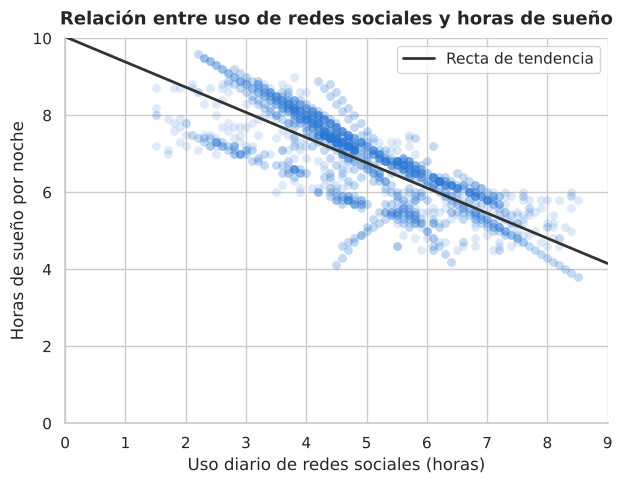

Correlación entre uso diario y horas de sueño: -0.79
Pendiente de la recta: -0.65 horas de sueño por cada hora adicional de uso


In [23]:
fig, ax = plt.subplots(figsize=(7, 5))

# Cada punto es un estudiante
ax.scatter(df["Avg_Daily_Usage_Hours"], df["Sleep_Hours_Per_Night"],
           s=40, color=COLOR, alpha=0.15, lw=0)

# Recta de tendencia (regresión lineal)
m, b = np.polyfit(df["Avg_Daily_Usage_Hours"], df["Sleep_Hours_Per_Night"], 1)
recorrido = np.linspace(0, 9, 100)
ax.plot(recorrido, m * recorrido + b, color="#333333", lw=2, label="Recta de tendencia")

ax.set_xlim(0, 9)
ax.set_ylim(0, 10)
ax.set_title("Relación entre uso de redes sociales y horas de sueño")
ax.set_xlabel(ETQ_USO)
ax.set_ylabel(ETQ_SUENO)
ax.legend()
plt.show()

r = df["Avg_Daily_Usage_Hours"].corr(df["Sleep_Hours_Per_Night"])
print(f"Correlación entre uso diario y horas de sueño: {r:.2f}")
print(f"Pendiente de la recta: {m:.2f} horas de sueño por cada hora adicional de uso")

**Interpretación:** Se observa una clara relación negativa entre ambas variables: a mayor uso de redes sociales, menos horas de sueño. La correlación es de **−0,79** y, según la recta de tendencia, cada hora adicional de uso diario se asocia en promedio con unas **0,65 horas menos de sueño**.

## 3.2 | ¿Cómo afecta esto al rendimiento académico?

¿Será que el impacto en lo académico se produce por la falta de sueño? Para explorarlo, se repite el gráfico anterior separando a los estudiantes que declaran que las redes afectan su rendimiento de los que no.

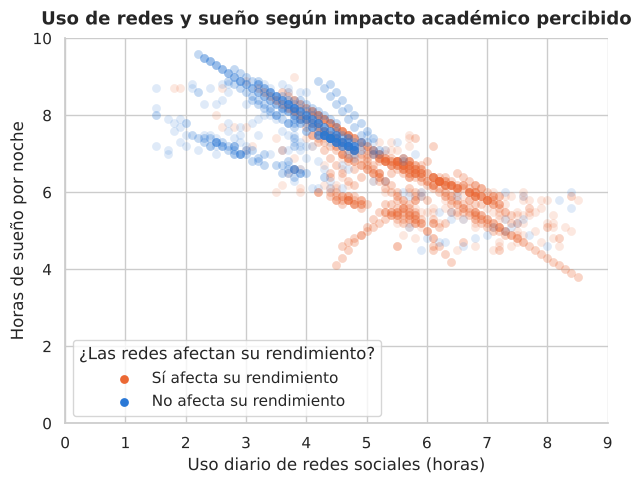

In [24]:
afectados = df[df["Affects_Academic_Performance"] == "Yes"]
no_afectados = df[df["Affects_Academic_Performance"] == "No"]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(afectados["Avg_Daily_Usage_Hours"], afectados["Sleep_Hours_Per_Night"],
           s=40, color=COLORES_AFECTA["Sí"], alpha=0.15, lw=0, label="Sí afecta su rendimiento")
ax.scatter(no_afectados["Avg_Daily_Usage_Hours"], no_afectados["Sleep_Hours_Per_Night"],
           s=40, color=COLORES_AFECTA["No"], alpha=0.15, lw=0, label="No afecta su rendimiento")

ax.set_xlim(0, 9)
ax.set_ylim(0, 10)
ax.set_title("Uso de redes y sueño según impacto académico percibido")
ax.set_xlabel(ETQ_USO)
ax.set_ylabel(ETQ_SUENO)
leyenda = ax.legend(title="¿Las redes afectan su rendimiento?")
for marca in leyenda.legend_handles:
    marca.set_alpha(1)            # la leyenda se muestra con el color sin transparencia
plt.show()

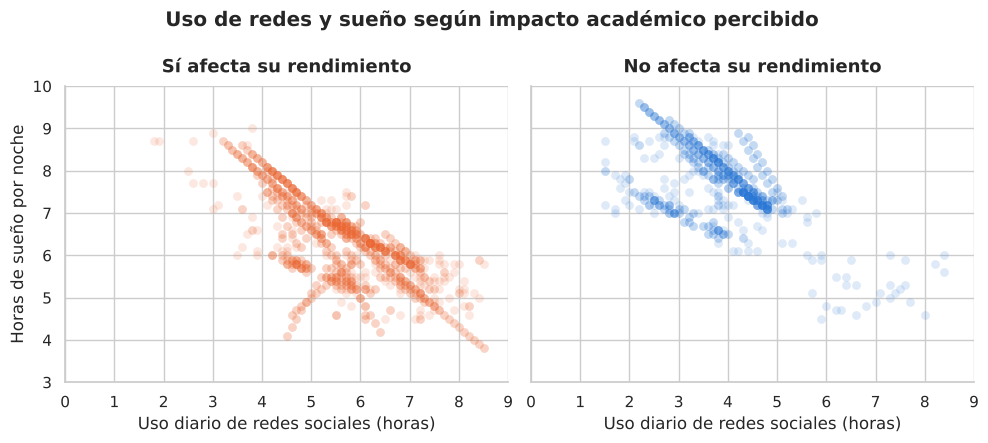

In [25]:
# Mismo gráfico, con cada grupo en un panel para evitar la superposición de puntos
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)

for eje, grupo, nombre, clave in [(ax[0], afectados, "Sí afecta su rendimiento", "Sí"),
                                  (ax[1], no_afectados, "No afecta su rendimiento", "No")]:
    eje.scatter(grupo["Avg_Daily_Usage_Hours"], grupo["Sleep_Hours_Per_Night"],
                s=40, color=COLORES_AFECTA[clave], alpha=0.15, lw=0)
    eje.set_title(nombre)
    eje.set_xlabel(ETQ_USO)

ax[0].set_ylabel(ETQ_SUENO)
ax[0].set_xlim(0, 9)
ax[0].set_ylim(3, 10)
fig.suptitle("Uso de redes y sueño según impacto académico percibido", fontweight="bold")
plt.tight_layout()
plt.show()

Se puede observar que quienes declaran que su desempeño académico se ve perjudicado se concentran en la zona de más horas de uso de redes y menos horas de sueño.

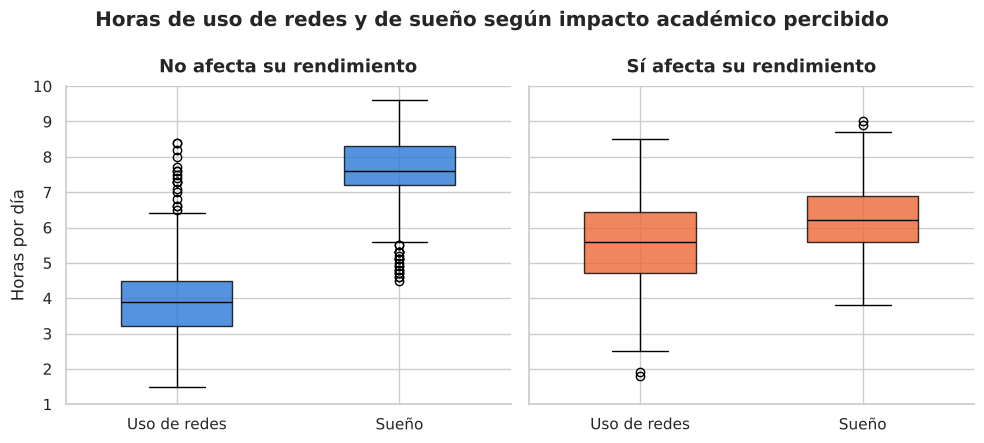

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)

for eje, grupo, nombre, clave in [(ax[0], no_afectados, "No afecta su rendimiento", "No"),
                                  (ax[1], afectados, "Sí afecta su rendimiento", "Sí")]:
    cajas = eje.boxplot([grupo["Avg_Daily_Usage_Hours"], grupo["Sleep_Hours_Per_Night"]],
                        tick_labels=["Uso de redes", "Sueño"], patch_artist=True, widths=0.5,
                        medianprops={"color": "black"})
    for caja in cajas["boxes"]:
        caja.set_facecolor(COLORES_AFECTA[clave])
        caja.set_alpha(0.8)
    eje.set_title(nombre)

ax[0].set_ylabel("Horas por día")
ax[0].set_ylim(1, 10)
fig.suptitle("Horas de uso de redes y de sueño según impacto académico percibido", fontweight="bold")
plt.tight_layout()
plt.show()

### Resumen numérico

Para cuantificar lo que muestran los gráficos, se calculan para cada grupo la media y la mediana de las horas de uso y de sueño, y el porcentaje de estudiantes que duerme **menos de 7 horas**, el mínimo recomendado para adultos.

In [27]:
resumen_academico = df.groupby("Affects_Academic_Performance").agg(
    estudiantes=("Student_ID", "count"),
    uso_media=("Avg_Daily_Usage_Hours", "mean"),
    uso_mediana=("Avg_Daily_Usage_Hours", "median"),
    sueno_media=("Sleep_Hours_Per_Night", "mean"),
    sueno_mediana=("Sleep_Hours_Per_Night", "median"),
    duerme_menos_7h_pct=("Sleep_Hours_Per_Night", lambda horas: (horas < 7).mean() * 100),
).round(2)

resumen_academico.rename(index=NOMBRES)

,estudiantes,uso_media,uso_mediana,sueno_media,sueno_mediana,duerme_menos_7h_pct
Affects_Academic_Performance,,,,,,
No,643,3.88,3.9,7.65,7.6,13.06
Sí,1100,5.62,5.6,6.27,6.2,76.64


**Interpretación:** El 63 % de los estudiantes (1.100 de 1.743) declara que las redes afectan su rendimiento académico. Este grupo usa las redes en promedio **5,62 horas por día**, contra 3,88 horas de quienes no se sienten afectados (1,7 horas más), y duerme **6,27 horas**, contra 7,65 (1,4 horas menos). Las medianas son casi iguales a las medias, por lo que la diferencia no se debe a unos pocos casos extremos.

La diferencia más marcada aparece en el descanso: **el 77 % de los que se sienten afectados duerme menos de 7 horas**, contra el 13 % del otro grupo.

## 3.3 | Conclusión (sueño y rendimiento académico)

Los datos muestran una asociación consistente entre las tres variables:

- **Uso y sueño:** a más horas de uso de redes sociales, menos horas de sueño (correlación de −0,79; unas 0,65 horas menos de sueño por cada hora adicional de uso).
- **Sueño y rendimiento:** quienes declaran que las redes afectan su rendimiento usan más las redes y duermen menos. Tres de cada cuatro duermen por debajo de las 7 horas recomendadas, contra uno de cada ocho entre quienes no se sienten afectados.

Esto es coherente con la idea de que parte del impacto académico de las redes se da a través de la falta de sueño, pero el análisis no permite confirmarlo: es descriptivo, el rendimiento es autodeclarado y no una medición de las notas, y los datos incluyen los registros duplicados mencionados en la Parte 1.

---

# Parte 4 | ¿Hay redes sociales que impactan más que otras? ¿Existe una brecha de género?

Esta parte realiza su propia carga y exploración del dataset, en la que se detecta que existen **filas duplicadas** ocultas por la columna `Relationship_Status` (ver la aclaración de la Parte 1). Por eso, a diferencia de las partes anteriores, aquí se trabaja con el dataset **sin duplicados** (1.038 estudiantes) y se crean nuevas variables (`Plataforma`, `Afecta_Rendimiento`, `Nivel_Uso`).

## 4.1 | Carga y exploración inicial

In [28]:
# Volvemos a cargar el dataset original, con todas sus columnas.
url = "https://raw.githubusercontent.com/Chaile-Mendez/tp-analisis-labo/main/data/raw/dataset_final"

df = pd.read_csv(url)

In [29]:
print("Países distintos:", df["Country"].nunique())
print("Rango de edad   :", df["Age"].min(), "a", df["Age"].max())
print("\nEstudiantes por género:")
print(df["Gender"].value_counts())
print("\nEstudiantes por plataforma más usada:")
print(df["Most_Used_Platform"].value_counts())

Países distintos: 110
Rango de edad   : 18 a 24

Estudiantes por género:
Gender
Male      883
Female    860
Name: count, dtype: int64

Estudiantes por plataforma más usada:
Most_Used_Platform
Instagram    550
TikTok       350
Facebook     295
WhatsApp     108
Twitter      103
LinkedIn      87
YouTube       75
Snapchat      73
WeChat        30
LINE          24
KakaoTalk     24
VKontakte     24
Name: count, dtype: int64


**Interpretación:** El dataset tiene 1.743 filas (estudiantes) de 18 a 24 años de 110 países, la distribución de género es bastante pareja, aunque hay más varones (883 varones y 860 mujeres). Hay **12 plataformas o redes**, muy desbalanceadas: Instagram (550) y TikTok (350) concentran más de la mitad de los casos, mientras que WeChat, LINE, KakaoTalk y VKontakte tienen 30 o menos observaciones cada una. Esto condiciona las comparaciones entre plataformas. Por ejemplo: los promedios de Instagram o TikTok, van a ser más estables, mientras que los de WeChat o LINE pueden moverse mucho por 1 o 2 estudiantes.

## 4.2 | Calidad de los datos

Contamos los **nulos** por columna con `isnull().sum()`, las filas **duplicadas** con `duplicated().sum()`. También utilizamos `describe()` para ver estadísticos como máximos y mínimos.
Además, nos va a servir para revisar el identificador `Student_ID`. Si identifica a cada estudiante, no debería repetirse.

In [30]:
print("Nulos por columna:")
print(df.isnull().sum())                                 # isnull() marca cada celda vacía; sum() las cuenta por columna
print("\nFilas duplicadas:", df.duplicated().sum())       # duplicated() marca las filas idénticas a otra anterior

Nulos por columna:
Student_ID                         0
Age                                0
Gender                             0
Academic_Level                     0
Country                            0
Avg_Daily_Usage_Hours              0
Most_Used_Platform                 0
Affects_Academic_Performance       0
Sleep_Hours_Per_Night              0
Mental_Health_Score                0
Relationship_Status             1038
dtype: int64

Filas duplicadas: 0


In [31]:
df.describe().round(2)

,Student_ID,Age,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,1743.00,1743.00,1743.00,1743.00,1743.00
mean,381.69,20.73,4.98,6.78,6.21
std,228.75,1.51,1.40,1.16,1.15
min,1.00,18.00,1.50,3.80,4.00
25%,188.50,19.00,4.00,5.90,5.00
50%,376.00,21.00,4.80,6.80,6.00
75%,562.00,22.00,5.90,7.60,7.00
max,1000.00,24.00,8.50,9.60,9.00


 Vemos que el `describe()` muestra un ID máximo de 1.000 con 1.743 filas, sospechamos que hay números repetidos, así que los contamos.

In [32]:
print("Student_ID repetidos:", df["Student_ID"].duplicated().sum(), "de", len(df), "filas")

Student_ID repetidos: 942 de 1743 filas


`Relationship_Status` tiene muchísimos nulos y `duplicated()` no encuentra nada, pero los `Student_ID` **se repiten** muchas veces. Sospechamos que las filas repetidas son el mismo estudiante cargado dos veces, y que el campo `Relationship_Status`  hace que parezcan filas distintas. Vamos a comprobarlo mediante un ejemplo: miramos un ID repetido y repetimos la búsqueda de duplicados **sin esa columna**.

In [33]:
# Las filas con Student_ID = 2
display(df[df["Student_ID"] == 2])

# Duplicados ignorando Relationship_Status
sin_relacion = df.drop(columns="Relationship_Status")
print("Duplicados ignorando Relationship_Status:", sin_relacion.duplicated().sum())

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
8,2,23,Female,Undergraduate,USA,2.7,YouTube,No,7.8,7.7,NaN
334,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8.0,NaN
1039,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8.0,Single


Duplicados ignorando Relationship_Status: 705


Como pudimos observar con el ejemplo, hay **705 filas repetidas**: son el mismo estudiante cargado dos veces, una con `Relationship_Status` vacío y otra con ese dato completo. (En el ejemplo del ID 2, las filas de India son el mismo estudiante; la de USA es otra persona que comparte el número.) Si no se las elimina, cada uno de esos estudiantes se cuenta dos veces y se inflan las muestras o promedios.

**Conclusiones:**

- `Relationship_Status` tiene **1.038 nulos**; es la única columna con faltantes.
- Hay **705 filas duplicadas** que no se detectaban por culpa de esa columna.
- No identificamos outliers: uso diario entre 1,5 y 8,5 horas, sueño entre 3,8 y 9,6 horas y salud mental entre 4 y 9 (a mayor puntaje, mejor salud mental).

## 4.3 | Pregunta de investigación

### a) ¿Cuál es la pregunta?

**¿Hay redes sociales que impactan más que otras sobre los estudiantes y existe una brecha de género en ese impacto?**

El impacto lo vamos a medir teniendo en cuenta las siguientes columnas del dataset: horas de uso diario (`Avg_Daily_Usage_Hours`), horas de sueño (`Sleep_Hours_Per_Night`), salud mental (`Mental_Health_Score`, más alto = mejor) y percepción de afectación académica (`Affects_Academic_Performance`).

### b) ¿Por qué vale la pena responderla?

Hablar de "redes sociales" en general esconde que no todas se usan igual, pueden tener efectos muy distintos. Identificar cuáles se asocian con peor bienestar, salud mental o calidad de vida, permite sacar conclusiones más enriquecedoras y así poder brindar recomendaciones más específicas. Además, podemos identificar si existe una brecha de género en ese impacto.

### c) ¿Qué respuesta encontramos?

**1. ¿Hay redes que impactan más que otras? Sí.** Los estudiantes que usan principalmente **WhatsApp, TikTok y Snapchat** pasan más horas en las redes, duermen menos, tienen peor salud mental y más afectación académica (en WhatsApp, el 100 % dice que las redes afectan su rendimiento). Los que usan **LinkedIn, Twitter y Facebook** tienen los resultados más favorables. Sin embargo, gran parte de esta diferencia se debe a las **horas de uso**, cuando comparamos estudiantes que usan las redes una cantidad de horas parecida, las diferencias entre plataformas se achican bastante; persisten entre quienes usan las redes hasta 6 horas por día, pero entre quienes las usan más de 6 horas el orden entre plataformas se mezcla.

**2. ¿Hay brecha de género? Muy leve, es decir, no es significativa.** Mujeres y varones tienen resultados muy parecidos en horas de uso, sueño, salud mental y afectación académica. En salud mental la diferencia es de solo 0,10 puntos (6,15 las mujeres y 6,25 los varones), y dentro de cada plataforma las diferencias también son chicas. Donde sí vemos una diferencia mayor es en el uso de cada plataforma: Instagram la usan más mujeres, y Facebook y WhatsApp, más varones.

## 4.4 | Transformaciones y resumen estadístico

### Transformaciones justificadas (limpieza)

**Transformación 1: eliminar `Relationship_Status`.** Es la única columna del dataset con nulos y no es relevante para las dos preguntas. Se elimina la columna y se conservan todas las filas. Al conservar las filas, damos paso a la siguiente transformación.

In [34]:
df = df.drop(columns=["Relationship_Status"])      # se elimina solo la columna; las filas quedan
print(df.columns.tolist())

['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Country', 'Avg_Daily_Usage_Hours', 'Most_Used_Platform', 'Affects_Academic_Performance', 'Sleep_Hours_Per_Night', 'Mental_Health_Score']


**Transformación 2: eliminar filas duplicadas.** Como vimos en el apartado de calidad de los datos (4.2), donde además lo comprobamos con un ejemplo, una fila que aparece dos veces es el mismo estudiante cargado dos veces. Con `drop_duplicates()` dejamos **una sola copia** de cada fila idéntica.

In [35]:
n_inicial = len(df)

# Si dos filas son idénticas en todas las columnas, es el mismo estudiante cargado dos veces, dejamos una sola.
df = df.drop_duplicates().reset_index(drop=True)

print("Filas antes     :", n_inicial)
print("Filas eliminadas:", n_inicial - len(df))
print("Filas ahora     :", len(df))
print("Filas duplicadas que quedan:", df.duplicated().sum())

Filas antes     : 1743
Filas eliminadas: 705
Filas ahora     : 1038
Filas duplicadas que quedan: 0


Podemos ver que quedan **1.038 filas (estudiantes)**.
Aclaración: algunos `Student_ID` siguen apareciendo más de una vez, pero esas filas no son duplicados, corresponden a estudiantes distintos (otro género, otro país, otra edad) que comparten el mismo número. Volvemos a hacer un ejemplo para verificarlo (tomamos el ID 1).

In [36]:
print("Student_ID que todavía se repiten:", df["Student_ID"].duplicated().sum())
df[df["Student_ID"] == 1]       # dos personas distintas con el mismo ID, no se eliminan

Student_ID que todavía se repiten: 237


,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score
319,1,22,Male,High School,USA,4.0,Twitter,No,7.6,8.6
333,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6.0


Como las filas del ID 1 difieren en género, edad, país y plataforma, son estudiantes distintos y se conservan. Borrarlas por tener el mismo ID habría eliminado a personas reales del análisis. Por lo tanto concluimos que `Student_ID` no identifica de forma única a cada estudiante.

### Transformaciones justificadas (columnas nuevas)

**Transformación 3: agrupamos redes sociales con pocas observaciones.** WeChat, LINE, KakaoTalk y VKontakte tienen entre 12 y 15 casos cada una, con tan pocos datos, sus promedios son inestables. Por lo tanto, las agrupamos en una categoría llamada **"Otras"**, y las 8 plataformas restantes (con más de 50 casos cada una) se mantienen separadas.

In [37]:
# 1) Contamos cuántos estudiantes tiene cada plataforma
conteo = df["Most_Used_Platform"].value_counts()

# 2) Filtro: las plataformas con menos de 20 estudiantes son las que se agrupan en "Otras"
minoritarias = conteo[conteo < 20].index.tolist()
print("Plataformas con menos de 20 estudiantes (se agrupan en 'Otras'):", minoritarias)

# 3) Creamos la columna nueva, esas plataformas o redes pasan a llamarse "Otras"
df["Plataforma"] = df["Most_Used_Platform"].replace({"WeChat": "Otras", "LINE": "Otras", "KakaoTalk": "Otras", "VKontakte": "Otras"})

# 4) Verificamos el resultado
df["Plataforma"].value_counts()

Plataformas con menos de 20 estudiantes (se agrupan en 'Otras'): ['WeChat', 'LINE', 'KakaoTalk', 'VKontakte']


Plataforma
Instagram    301
TikTok       196
Facebook     172
Twitter       73
LinkedIn      66
YouTube       65
Snapchat      60
WhatsApp      54
Otras         51
Name: count, dtype: int64

**Transformación 4: impacto académico.** `Affects_Academic_Performance` muestra "Yes"/"No". Se crea `Afecta_Rendimiento` (1 = Sí, 0 = No) para pasar de texto a números y poder operar sobre la columna. Además, como la columna solo tiene unos y ceros, su promedio es la proporción de estudiantes que dicen que las redes afectan su rendimiento. Por ejemplo, un promedio de 0,33 significa que el 33 % respondió "Sí".

In [38]:
df["Afecta_Rendimiento"] = (df["Affects_Academic_Performance"] == "Yes").astype(int)   # 1 si dice que sí, 0 si no
df[["Affects_Academic_Performance", "Afecta_Rendimiento"]].value_counts()

Affects_Academic_Performance  Afecta_Rendimiento
Yes                           1                     647
No                            0                     391
Name: count, dtype: int64

**Transformación 5: nivel de uso diario.** Con `pd.cut` se clasifica el uso en tres niveles (**Bajo**: hasta 4 h, **Medio**: entre 4 y 6 h, **Alto**: más de 6 h). Esto nos va a servir para comparar plataformas entre estudiantes que usan las redes una cantidad de horas parecida, y así ver si las diferencias se deben a la plataforma o solo a las horas de uso.

In [39]:
df["Nivel_Uso"] = pd.cut(df["Avg_Daily_Usage_Hours"],
                         bins=[0, 4, 6, 10],
                         labels=["Bajo (≤4 h)", "Medio (4-6 h)", "Alto (>6 h)"])
df["Nivel_Uso"].value_counts().sort_index()

Nivel_Uso
Bajo (≤4 h)      278
Medio (4-6 h)    493
Alto (>6 h)      267
Name: count, dtype: int64

El nivel Medio es el más numeroso, 493 estudiantes usan las redes entre 4 y 6 horas por día, contando todas las plataformas o redes. Le siguen el nivel Bajo (278) y el Alto (267), que tienen una cantidad parecida de estudiantes.

### Resumen estadístico por grupo (`groupby`)

**Agrupación 1: por plataforma.** Con `groupby` y `agg` calculamos la media de cada indicador y la cantidad de estudiantes, ordenado de peor a mejor salud mental.

In [40]:
por_plataforma = df.groupby("Plataforma").agg(
    uso_horas=("Avg_Daily_Usage_Hours", "mean"),
    sueno_horas=("Sleep_Hours_Per_Night", "mean"),
    salud_mental=("Mental_Health_Score", "mean"),
    afecta_rendimiento=("Afecta_Rendimiento", "mean"),     # proporción de estudiantes afectados
    estudiantes=("Student_ID", "count"),
).sort_values("salud_mental")

display(por_plataforma.round(2))

,uso_horas,sueno_horas,salud_mental,afecta_rendimiento,estudiantes
Plataforma,,,,,
WhatsApp,6.48,5.87,5.54,1.00,54
TikTok,5.38,6.32,5.77,0.85,196
Snapchat,5.54,6.01,5.81,0.77,60
Instagram,4.88,6.96,6.15,0.65,301
YouTube,4.91,6.51,6.34,0.52,65
Facebook,4.83,7.08,6.51,0.41,172
Twitter,4.89,6.67,6.57,0.51,73
LinkedIn,4.23,6.82,6.77,0.33,66
Otras,4.34,7.61,6.84,0.39,51


**Interpretación:** Observamos grandes diferencias entre plataformas: **WhatsApp** muestra los resultados más preocupantes: más horas de uso (6,5 h), menos sueño (5,9 h), la peor salud mental (5,54) y el 100 % de sus estudiantes declararon que les afecta académicamente. Después está **TikTok**, que muestra en el indicador de salud mental un (5,77) y **Snapchat** (5,81). El grupo "Otras" muestra 6,84 en salud mental, **LinkedIn** (6,77), **Twitter** (6,57) y **Facebook** (6,51), por lo que podemos decir que muestran una mejor salud mental, ademas de más sueño y menor afectación académica. Instagram, la más usada, queda en una posición intermedia (6,15).

**Agrupación 2: por género.** Misma tabla, solo agregamos la mediana de salud mental, además de la media, para ver si hay brecha de género.

In [41]:
por_genero = df.groupby("Gender").agg(
    uso_horas=("Avg_Daily_Usage_Hours", "mean"),
    sueno_horas=("Sleep_Hours_Per_Night", "mean"),
    salud_mental=("Mental_Health_Score", "mean"),
    salud_mental_mediana=("Mental_Health_Score", "median"),
    afecta_rendimiento=("Afecta_Rendimiento", "mean"),
    estudiantes=("Student_ID", "count"),
)
display(por_genero.round(2))

,uso_horas,sueno_horas,salud_mental,salud_mental_mediana,afecta_rendimiento,estudiantes
Gender,,,,,,
Female,5.08,6.68,6.15,6.0,0.63,507
Male,4.96,6.76,6.25,6.0,0.62,531


**Interpretación:** Observamos que las diferencias por género son **muy chicas**, mujeres y varones usan las redes alrededor de 5 horas por día (5,08 contra 4,96), duermen cerca de 6,7 horas y la afectación al rendimiento academico es casi idéntica (63 % contra 62 %). En salud mental los varones promedian 6,25 y las mujeres 6,15, una diferencia de **0,10 puntos**, con la misma mediana. En el promedio general no aparece una brecha de género relevante.

**Agrupación 3: plataforma × género.** Se analiza el indicador de **salud mental** (`Mental_Health_Score`),  y se calcula su **promedio para mujeres y para varones dentro de cada plataforma**, para ver si la brecha de género aparece en alguna red en particular. Para eso se usa `pivot_table`: las plataformas van en las filas, el género en las columnas y los valores son el promedio de salud mental.

La columna **Brecha (varones − mujeres)** resta ambos promedios: un valor **positivo** significa que los varones tienen un puntaje de salud mental más alto que las mujeres, y uno **negativo**, que las mujeres tienen un puntaje más alto.

Después, con `crosstab`, se cuenta **cuántas mujeres y cuántos varones hay en cada plataforma**. Esto es importante porque algunas combinaciones tienen pocos estudiantes y sus promedios son menos confiables.

In [42]:
salud_pg = df.pivot_table(index="Plataforma", columns="Gender", values="Mental_Health_Score", aggfunc="mean")
salud_pg["Brecha (varones - mujeres)"] = salud_pg["Male"] - salud_pg["Female"]
display(salud_pg.round(2))

print("Cantidad de estudiantes por plataforma y género:")
display(pd.crosstab(df["Plataforma"], df["Gender"]))

Gender,Female,Male,Brecha (varones - mujeres)
Plataforma,,,
Facebook,6.37,6.58,0.21
Instagram,6.19,6.08,-0.11
LinkedIn,6.71,6.82,0.11
Otras,6.86,6.83,-0.03
Snapchat,5.61,6.03,0.42
TikTok,5.69,5.86,0.16
Twitter,6.63,6.54,-0.09
WhatsApp,5.36,5.58,0.22
YouTube,6.30,6.38,0.08


Cantidad de estudiantes por plataforma y género:


Gender,Female,Male
Plataforma,,
Facebook,52,120
Instagram,193,108
LinkedIn,30,36
Otras,28,23
Snapchat,32,28
TikTok,106,90
Twitter,29,44
WhatsApp,11,43
YouTube,26,39


**Interpretación:** Dentro de cada plataforma las brechas son chicas (0,42 puntos o menos) y **cambian de signo**: en Instagram, Twitter y "Otras", es decir, en ellas las mujeres tienen un puntaje levemente mayor, y en Snapchat, WhatsApp o Facebook el de los varones es algo mayor. Snapchat tiene la mayor diferencia (0,42), y observamos que aunque hay más mujeres que varones (32 mujeres y 28 varones) el puntaje de los varones es algo mayor, pero también hay que tener en cuenta que son pocos estudiantes en comparación con Instagram o TikTok.

En cuanto a la cantidad de estudiantes mujeres y varones dentro de cada plataforma, se observa una diferencia algo mayor: Instagram es mayoritariamente femenina (193 mujeres y 108 varones), mientras que Facebook (120 varones y 52 mujeres) y WhatsApp (43 varones y 11 mujeres) son mayoritariamente masculinas. Por lo tanto, concluimos que el género no es la causa de que unas plataformas tengan mejor o peor salud mental que otras.

**Agrupación 4: control por nivel de uso.** Las plataformas con más horas de uso podrían indicar peor salud mental simplemente por el tiempo que se las utiliza. Para verificarlo comparamos la salud mental dentro de cada nivel de uso (la tabla muestra `NaN` donde no hay estudiantes en esa combinación).

In [43]:
control = df.pivot_table(index="Plataforma", columns="Nivel_Uso", values="Mental_Health_Score", aggfunc="mean", observed=True)  # observed=True: solo toma en cuenta los niveles que existen en los datos
display(control.round(2))

# Salud mental promedio de cada nivel de uso (sin separar por plataforma).
# Sirve para ver si a más horas de uso hay peor salud mental.
print("Salud mental promedio por nivel de uso:")
print(df.groupby("Nivel_Uso", observed=True)["Mental_Health_Score"].mean().round(2))

# Correlación entre horas de uso y salud mental: va de -1 a 1.
# Un valor negativo cercano a -1 indica que, a más horas de uso, menor salud mental.
print("\nCorrelación entre uso diario y salud mental:", round(df["Avg_Daily_Usage_Hours"].corr(df["Mental_Health_Score"]), 2))

Nivel_Uso,Bajo (≤4 h),Medio (4-6 h),Alto (>6 h)
Plataforma,,,
Facebook,7.64,6.63,4.86
Instagram,7.42,6.04,4.72
LinkedIn,7.82,6.17,4.64
Otras,7.67,6.39,NaN
Snapchat,7.43,5.87,4.99
TikTok,7.11,5.89,4.87
Twitter,7.49,6.72,5.05
WhatsApp,NaN,5.82,5.41
YouTube,7.46,5.98,5.09


Salud mental promedio por nivel de uso:
Nivel_Uso
Bajo (≤4 h)      7.51
Medio (4-6 h)    6.16
Alto (>6 h)      4.93
Name: Mental_Health_Score, dtype: float64

Correlación entre uso diario y salud mental: -0.82


**Interpretación:** Cuantas más horas se usan las redes, peor es la salud mental (correlación de −0,82). El puntaje promedio baja de 7,51 en el uso bajo, a 6,16 en el medio y a 4,93 en el alto.

Cuando comparamos plataformas entre estudiantes que usan las redes una cantidad de horas parecida, las diferencias entre plataformas se achican: pasan de 1,3 puntos a entre 0,7 y 0,9. Esto significa que **gran parte de la diferencia entre plataformas se debe a las horas de uso y no a la plataforma en sí**.

Aun así, en los niveles de uso bajo y medio la diferencia no desaparece: entre quienes usan las redes de 4 a 6 horas, TikTok (5,89) y Snapchat (5,87) siguen por debajo de Facebook (6,63) y Twitter (6,72). En cambio, entre quienes las usan más de 6 horas el orden se mezcla: Facebook (4,86) queda a la par de TikTok (4,87), WhatsApp pasa a tener el mejor promedio (5,41) y LinkedIn el peor (4,64). Es decir, con un uso muy intensivo la plataforma deja de marcar una diferencia clara.

Las diferencias que persisten pueden tener dos explicaciones: que esas plataformas afecten más la salud mental, o que las personas que las eligen sean distintas (por ejemplo, que ya estuvieran peor antes de usarlas). Con estos datos no podemos saber cuál es la correcta.

## 4.5 | Análisis gráfico

Se presentan cuatro gráficos de tres tipos distintos: **distribución**, **comparación entre categorías** y **relación entre dos variables**. Cada uno lleva título, ejes etiquetados e interpretación.

**Gráfico 1. Distribución:** Primero vamos a analizar la siguiente pregunta: ¿cómo se reparte el puntaje de salud mental entre mujeres y varones? Para visualizarla realizamos un histograma comparativo (entre géneros) que muestra la distribución completa, no solo el promedio.

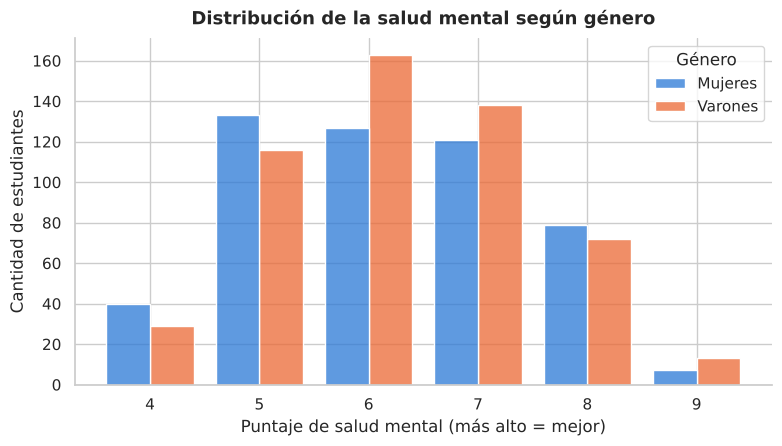

In [44]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=df.assign(Genero=df["Gender"].map(NOMBRES)), x="Mental_Health_Score",
             hue="Genero", hue_order=["Mujeres", "Varones"], palette=COLORES_GENERO,
             multiple="dodge", discrete=True, shrink=0.8, ax=ax)
ax.get_legend().set_title("Género")
ax.set_title("Distribución de la salud mental según género")
ax.set_xlabel(ETQ_SALUD)
ax.set_ylabel("Cantidad de estudiantes")
plt.show()

**Interpretación:** Los puntajes de salud mental de mujeres y varones se reparten de forma muy parecida, van del mismo mínimo, al mismo máximo. En ambos casos la mayoría está entre 5 y 7. Por lo tanto, podemos concluir que **no hay una brecha de género importante en salud mental**.

**Gráfico 2. Comparación entre categorías:** En este gráfico vamos a visualizar la siguiente pregunta: ¿qué plataforma se asocia con mejor o peor salud mental? Para eso realizamos un gráfico de barras ordenadas con la cantidad de estudiantes sobre cada una.

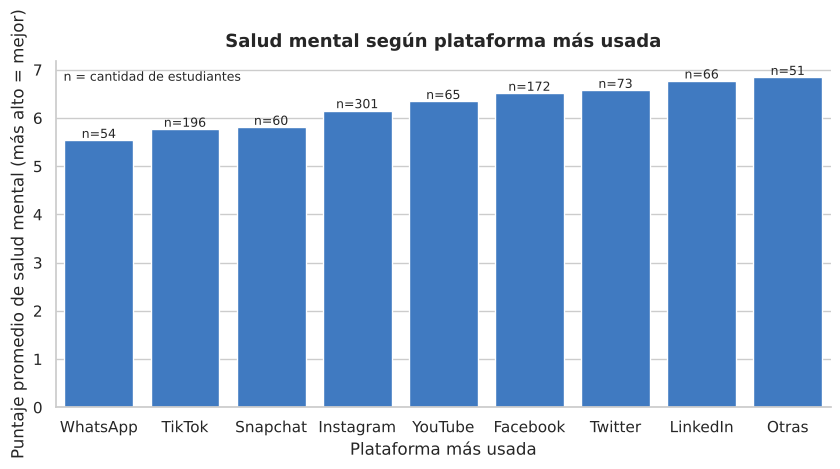

In [45]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=por_plataforma.index, y=por_plataforma["salud_mental"], color=COLOR, ax=ax)   # una barra por plataforma
for i, fila in enumerate(por_plataforma.itertuples()):
    ax.text(i, fila.salud_mental + 0.05, f"n={fila.estudiantes}", ha="center", fontsize=9)  # cantidad de casos
ax.text(0.01, 0.97, "n = cantidad de estudiantes", transform=ax.transAxes, va="top", fontsize=9)   # definimos qué es n para que no haya confusión
ax.set_title("Salud mental según plataforma más usada")
ax.set_xlabel("Plataforma más usada")
ax.set_ylabel(ETQ_SALUD_PROM)
plt.show()

**Interpretación:** Observamos que los usuarios de **WhatsApp, TikTok y Snapchat** tienen el peor promedio de salud mental, y los de **LinkedIn, Twitter, Facebook y el grupo "Otras"**, el mejor. Una posible interpretación a esto es que las plataformas de uso constante y alta frecuencia se asocian con más horas de pantalla, mientras que las de uso más puntual se asocian con menos. Es una hipótesis, por lo tanto no prueba que la plataforma sea la causa.

Cabe destacar que como el eje arranca en cero, las barras se ven de alturas parecidas y la diferencia no resalta tanto. Pasar de 5,5 a 6,5 (aproximadamente, mirando el gráfico) se ve como una diferencia chica.

**Gráfico 3. Relación entre dos variables:** Para este gráfico, como relacionamos 2 variables, nos hacemos la siguiente pregunta: ¿las plataformas donde los estudiantes usan más horas las redes tienen peor salud mental? Para realizar la visualización se usa un **diagrama de dispersión**, en donde cada punto es una plataforma con sus **horas diarias de uso promedio** en el eje horizontal y su **puntaje promedio de salud mental** en el eje vertical. Así podemos observar si ambas variables se mueven juntas.

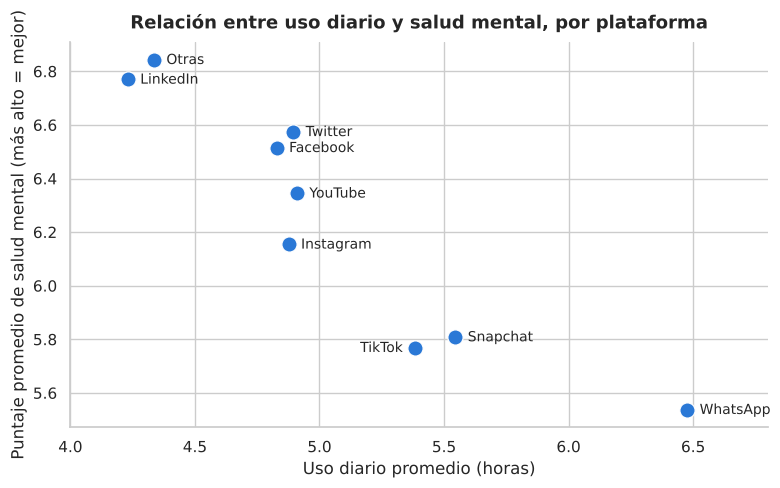

In [46]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=por_plataforma, x="uso_horas", y="salud_mental", s=120, color=COLOR, ax=ax)   # un punto por plataforma

# Escribimos el nombre de cada plataforma al lado de su punto (TikTok a la izquierda para que no tape a Snapchat)
for nombre, fila in por_plataforma.iterrows():
    izq = nombre == "TikTok"
    ax.annotate(nombre, (fila.uso_horas, fila.salud_mental), textcoords="offset points",
                xytext=(-9 if izq else 9, -3), ha="right" if izq else "left", fontsize=10)

ax.set_xlim(4.0, 6.8)    # margen en el eje horizontal para que entren los nombres
ax.set_title("Relación entre uso diario y salud mental, por plataforma")
ax.set_xlabel(ETQ_USO_PROM)
ax.set_ylabel(ETQ_SALUD_PROM)
plt.show()

**Interpretación:** Podemos notar que los puntos bajan de izquierda a derecha: cuantas más horas de uso promedio tiene una plataforma, menor es la salud mental promedio de sus estudiantes. **WhatsApp** es la que más horas acumula (6,5 h) y la que peor salud mental tiene (5,54). **TikTok** y **Snapchat** están en el medio de uso (alrededor de 5,4 y 5,5 h) y tienen puntajes bajos de salud mental (5,77 y 5,81). También observamos a **LinkedIn** y **"Otras"**, que tienen el menor uso (alrededor de 4,3 h) y los mejores puntajes de salud mental (6,77 y 6,84).

Con esto podemos concluir que el uso diario y la salud mental están relacionados: las plataformas con peor puntaje de salud mental son también aquellas en las que los estudiantes pasan más horas. Esto no prueba que las horas de uso sean la causa de la peor salud mental, solo muestra que ambas cosas aparecen juntas, es decir, existe una correlación, pero no podemos afirmar que hay causalidad.

---

# Parte 5 | ¿El uso de redes sociales afecta las relaciones sentimentales de los estudiantes?

Esta es la única parte que utiliza la variable `Relationship_Status`. Por ese motivo vuelve a cargar el dataset y, en lugar de eliminar la columna, se queda solo con las filas que tienen ese dato completo (`pareja = df.dropna()`). Esas filas no se repiten entre sí, por lo que esta parte no se ve afectada por los duplicados mencionados en la Parte 1.

## 5.1 | Carga de datos y estado sentimental de los estudiantes

Cargamos el dataset y contamos cuántos estudiantes hay en cada estado sentimental (columna `Relationship_Status`), que es la variable que organiza toda esta pregunta.

In [47]:
df = pd.read_csv(url)
pareja = df.dropna()
print(pareja["Relationship_Status"].value_counts())
pareja.head()

Relationship_Status
Single             384
In Relationship    289
Complicated         32
Name: count, dtype: int64


,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
1038,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6.0,In Relationship
1039,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8.0,Single
1040,3,20,Female,Undergraduate,USA,6.0,TikTok,Yes,5.0,5.0,Complicated
1041,4,18,Male,High School,UK,3.0,YouTube,No,7.0,7.0,Single
1042,5,21,Male,Graduate,Canada,4.5,Facebook,Yes,6.0,6.0,In Relationship


## 5.2 | Uso diario de redes según estado sentimental

Luego, calculamos la media y la mediana de las horas de uso diario (`Avg_Daily_Usage_Hours`) en función de la situación sentimental.

In [48]:
print(pareja.groupby("Relationship_Status")["Avg_Daily_Usage_Hours"].agg(["mean", "median"]))

                         mean  median
Relationship_Status                  
Complicated          4.721875    4.75
In Relationship      4.930796    4.70
Single               4.926042    4.80


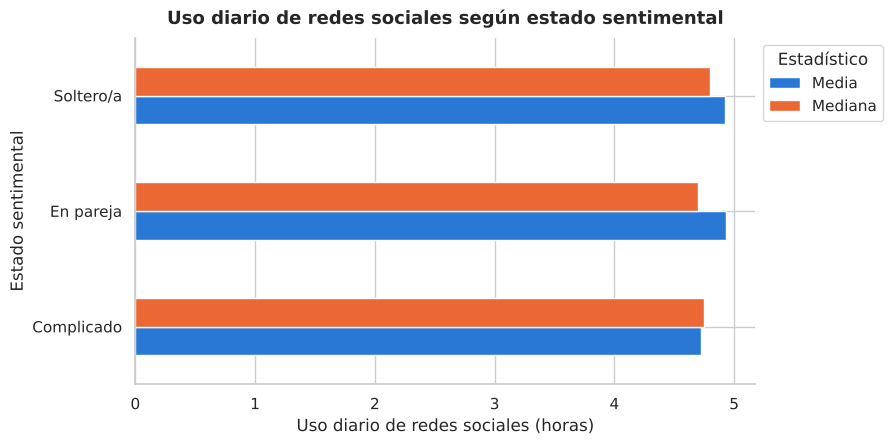

In [49]:
promedios = pareja.groupby("Relationship_Status")["Avg_Daily_Usage_Hours"].agg(["mean", "median"])
promedios = promedios.rename(index=NOMBRES, columns={"mean": "Media", "median": "Mediana"})

ax = promedios.plot(kind="barh", color=[AZUL, NARANJA])
ax.set_title("Uso diario de redes sociales según estado sentimental")
ax.set_ylabel("Estado sentimental")
ax.set_xlabel(ETQ_USO)
ax.legend(title="Estadístico", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

**Interpretación:** La media y la mediana del uso diario son muy parecidas en los tres grupos (entre 4,7 y 4,9 horas por día), por lo que no se observa una diferencia en la cantidad de uso de redes según la situación sentimental.

## 5.3 | Estado sentimental según la plataforma más usada

In [50]:
print(pareja["Most_Used_Platform"].value_counts())

Most_Used_Platform
Instagram    249
TikTok       154
Facebook     123
WhatsApp      54
Twitter       30
LinkedIn      21
WeChat        15
Snapchat      13
LINE          12
KakaoTalk     12
VKontakte     12
YouTube       10
Name: count, dtype: int64


Calculamos qué porcentaje de los usuarios de cada plataforma está soltero, en pareja o en una situación complicada, para ver si hay una relación entre la situación sentimental de los estudiantes y la red social que más usan.

In [51]:
rrss = pd.crosstab(pareja["Most_Used_Platform"], pareja["Relationship_Status"], normalize="index").mul(100).round(2)
rrss

Relationship_Status,Complicated,In Relationship,Single
Most_Used_Platform,,,
Facebook,0.81,57.72,41.46
Instagram,4.02,37.75,58.23
KakaoTalk,0.00,50.00,50.00
LINE,0.00,0.00,100.00
LinkedIn,23.81,38.10,38.10
Snapchat,30.77,30.77,38.46
TikTok,5.19,29.22,65.58
Twitter,0.00,46.67,53.33
VKontakte,0.00,50.00,50.00


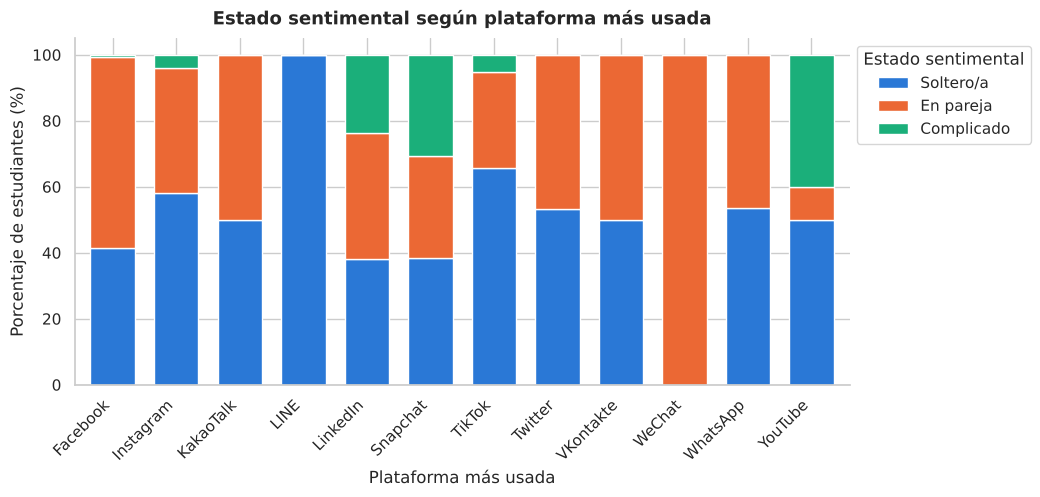

In [52]:
# Pasamos los nombres de las categorías al castellano y fijamos el orden de los segmentos
rrss_grafico = rrss.rename(columns=NOMBRES)[list(COLORES_ESTADO)]

ax = rrss_grafico.plot(kind="bar", stacked=True, figsize=(10, 4.5), width=0.7,
                       color=list(COLORES_ESTADO.values()), edgecolor="white", linewidth=1)
ax.set_title("Estado sentimental según plataforma más usada")
ax.set_xlabel("Plataforma más usada")
ax.set_ylabel("Porcentaje de estudiantes (%)")
ax.legend(title="Estado sentimental", loc="upper left", bbox_to_anchor=(1, 1))
plt.xticks(rotation=45, ha="right")
plt.show()

## 5.4 | Análisis sobre las plataformas más usadas

Como varias plataformas tienen pocas observaciones con este dato, decidimos hacer el análisis sobre las tres más usadas: Instagram, TikTok y Facebook.

In [53]:
top3 = pareja["Most_Used_Platform"].value_counts().nlargest(3).index
pareja_top3 = pareja[pareja["Most_Used_Platform"].isin(top3)]
print(pareja_top3["Most_Used_Platform"].value_counts())

Most_Used_Platform
Instagram    249
TikTok       154
Facebook     123
Name: count, dtype: int64


In [54]:
rrss_top3 = pd.crosstab(pareja_top3["Most_Used_Platform"], pareja_top3["Relationship_Status"], normalize="index").mul(100).round(2)
rrss_top3

Relationship_Status,Complicated,In Relationship,Single
Most_Used_Platform,,,
Facebook,0.81,57.72,41.46
Instagram,4.02,37.75,58.23
TikTok,5.19,29.22,65.58


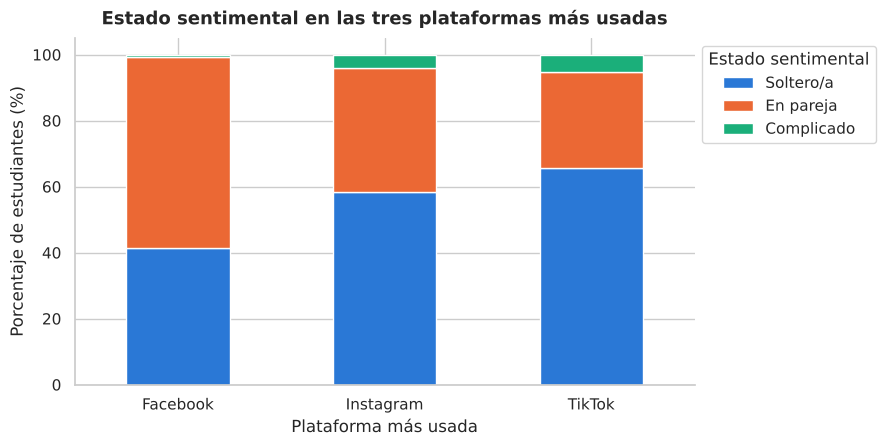

In [55]:
rrss_top3_grafico = rrss_top3.rename(columns=NOMBRES)[list(COLORES_ESTADO)]

ax = rrss_top3_grafico.plot(kind="bar", stacked=True, figsize=(8, 4.5), width=0.5,
                            color=list(COLORES_ESTADO.values()), edgecolor="white", linewidth=1)
ax.set_title("Estado sentimental en las tres plataformas más usadas")
ax.set_xlabel("Plataforma más usada")
ax.set_ylabel("Porcentaje de estudiantes (%)")
ax.legend(title="Estado sentimental", loc="upper left", bbox_to_anchor=(1, 1))
plt.xticks(rotation=0)
plt.show()

**Interpretación:** Entre las tres plataformas con más casos, la proporción de solteros es mayor en **TikTok (65,6 %)** y en **Instagram (58,2 %)**, mientras que en **Facebook** la mayoría está en pareja (57,7 %). Los casos en situación complicada también son algo más frecuentes en TikTok (5,2 %) e Instagram (4,0 %) que en Facebook (0,8 %), aunque son muy pocos estudiantes (8, 10 y 1), por lo que esa diferencia es poco confiable.

## 5.5 | Conclusión

La cantidad de uso de redes sociales es prácticamente igual entre solteros, estudiantes en pareja y en situación complicada, por lo que con estos datos **no se observa que el uso de redes afecte la situación sentimental**.

La diferencia aparece en **qué plataforma** se usa: los solteros tienen mayor peso entre los usuarios de TikTok e Instagram, y los estudiantes en pareja, entre los de Facebook. Esto describe el perfil de quienes eligen cada plataforma, no un efecto de la plataforma sobre las relaciones.

---

# Parte 6 | Síntesis final

A partir de los distintos análisis realizados sobre el dataset se pueden resumir las siguientes respuestas:

1. **Nivel de desarrollo (Parte 2):** el impacto no es igual para todos. Los estudiantes de países en desarrollo presentan, en promedio, más horas de uso, menos horas de sueño, peor salud mental y mayor afectación académica percibida.
2. **Sueño y rendimiento académico (Parte 3):** a mayor uso diario de redes sociales, menos horas de sueño. Los estudiantes que declaran que su desempeño académico se ve perjudicado usan más las redes y duermen menos: tres de cada cuatro duermen menos de 7 horas.
3. **Plataformas y género (Parte 4):** hay redes que se asocian con peores resultados (WhatsApp, TikTok y Snapchat) y otras con resultados más favorables (LinkedIn, Twitter y Facebook), aunque gran parte de la diferencia se explica por las horas de uso. La brecha de género es muy leve.
4. **Relaciones sentimentales (Parte 5):** el uso diario de redes es muy parecido entre estudiantes solteros, en pareja o en una situación complicada, por lo que con estos datos no se observa que el uso de redes afecte la situación sentimental.

En todos los casos los resultados son **descriptivos**: muestran asociaciones y diferencias entre grupos dentro de la muestra, pero no permiten establecer relaciones causales.

## Conclusión final

Las cuatro preguntas convergen en un mismo patrón: **la cantidad de horas de uso es el factor que más se repite detrás de los resultados menos favorables**. Los grupos con peores indicadores (estudiantes de países en desarrollo, quienes declaran que las redes afectan su rendimiento y los usuarios de WhatsApp, TikTok y Snapchat) son también los que más horas pasan en las redes, y a más horas de uso se observan menos horas de sueño y un menor puntaje de salud mental. En cambio, el género y la situación sentimental casi no muestran diferencias en la cantidad de uso ni en sus consecuencias.

Por lo tanto, más que qué red se usa o quién la usa, el dato más útil para anticipar un impacto negativo es **cuánto tiempo se le dedica**. Para confirmar esta relación haría falta un estudio que siga a los mismos estudiantes a lo largo del tiempo y que mida el rendimiento académico con datos objetivos, en lugar de la percepción de cada estudiante.